Resources for analysis:

* https://ucdavis-bioinformatics-training.github.io/2022-June-RNA-Seq-Analysis/data_analysis/DE_Analysis_mm_with_quizzes_fixed
* https://ucdavis-bioinformatics-training.github.io/2022-June-RNA-Seq-Analysis/data_reduction/03-counts_mm
* https://github.com/ben-laufer/RNA-seq/blob/main/04-limma-voom.R
* https://raw.githubusercontent.com/ucdavis-bioinformatics-training/2020-mRNA_Seq_Workshop/master/data_analysis/enrichment_mm.Rmd

I switched between batch 1 and 2 data by changing every instance of "batch1" to "batch2" and vice versa.

# Set Library Path

In [1]:
.libPaths("/home/vhaghani/anaconda3/envs/jupyter_nb_R4.4.2/lib/R/library")

# Load Libraries

In [3]:
library(edgeR)
library(rtracklayer)
library(gplots)
library(RColorBrewer)
library(dplyr)
library(ggplot2)

# Load Metadata

In [73]:
# Read in metadata
metadata <- read.csv("metadata_batch1.csv")

# Split metadata by gene to create named lists
metadata <- split(metadata, metadata$gene)

# Remove any empty data frames that might result from filtering
metadata <- metadata[sapply(metadata, nrow) > 0]

# View
str(metadata)

List of 1
 $ MECP2:'data.frame':	15 obs. of  10 variables:
  ..$ sample_number         : int [1:15] 4 5 6 7 8 9 43 44 45 79 ...
  ..$ count_file_sample_name: chr [1:15] "4_2024_044_1_S58" "5_2024_044_1_S65" "6_2024_044_1_S57" "7_2024_044_1_S55" ...
  ..$ sample_name           : chr [1:15] "2043_D_MECP2_WT_CtO_D46_1" "2043_D_MECP2_WT_CtO_D46_2" "2043_D_MECP2_WT_CtO_D46_3" "2043_A_MECP2_R270X_CtO_D46_1" ...
  ..$ gene                  : chr [1:15] "MECP2" "MECP2" "MECP2" "MECP2" ...
  ..$ genotype              : chr [1:15] "WT" "WT" "WT" "R270X" ...
  ..$ cell_type             : chr [1:15] "CtO" "CtO" "CtO" "CtO" ...
  ..$ time_point            : chr [1:15] "D46" "D46" "D46" "D46" ...
  ..$ group                 : chr [1:15] "MECP2_WT_CtO_D46" "MECP2_WT_CtO_D46" "MECP2_WT_CtO_D46" "MECP2_R270X_CtO_D46" ...
  ..$ replicate             : int [1:15] 1 2 3 1 2 3 1 2 1 1 ...
  ..$ WGCNA_name            : chr [1:15] "MECP2_WT_CtO_D46_Rep1" "MECP2_WT_CtO_D46_Rep2" "MECP2_WT_CtO_D46_Rep3" "MECP2

In [74]:
# View groups 
for (gene_name in names(metadata)) {
  cat("\n=== Group counts for", gene_name, "===\n")
  print(table(metadata[[gene_name]]$group))
}


=== Group counts for MECP2 ===

MECP2_1155del32_CtO_D111      MECP2_R270X_CtO_D18      MECP2_R270X_CtO_D46 
                       3                        2                        3 
        MECP2_WT_CtO_D18         MECP2_WT_CtO_D46       X80230F_WT_CtO_D11 
                       1                        3                        3 


# Load Counts

In [75]:
# Read in counts
counts <- read.delim("05_gene_counts/hgnc_counts.txt", row.names = 1)

# Fix column names
colnames(counts) <- gsub("^X", "", colnames(counts))
colnames(counts) <- gsub("\\.", "-", colnames(counts))
colnames(counts) <- gsub("_{2,}", "_", colnames(counts))
colnames(counts) <- trimws(colnames(counts))

# View
head(counts)

,100_2024_044_1_S45,101_2024_044_1_S27,10_2024_044_1_S72,102_2024_044_1_S20,103_2024_044_1_S8,104_2024_044_1_S9,105_2024_044_1_S11,106_2024_044_1_S17,107_2024_044_1_S14,108_2024_044_1_S3,⋯,SV1552_sg4-3_2024_044_2_S15,Y719X_P0_2024_044_2_S19,Y719X_P3_2024_044_2_S20,Y719X_P4_2024_044_2_S21,ZARDF_ORG_d18_N1_2024_044_2_S43,ZARDF_ORG_d18_N2_2024_044_2_S44,ZARDF_ORG_d18_N3_2024_044_2_S45,ZARDF_ORG_d46_N1_2024_044_2_S49,ZARDF_ORG_d46_N2_2024_044_2_S50,ZARDF_ORG_d46_N3_2024_044_2_S51
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
ENSG00000290825,0,0,4,0,6,0,0,3,2,0,⋯,0,0,0,0,0,0,0,0,100,0
DDX11L1,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
WASH7P,7,2,10,6,11,5,6,0,7,7,⋯,0,0,0,0,0,0,163,0,0,0
MIR6859-1,0,0,3,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
MIR1302-2HG,0,2,3,7,5,0,0,1,0,10,⋯,0,0,0,0,0,0,0,0,14,62
MIR1302-2,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0


In [76]:
# Read in metadata and select only the mapping columns to rename samples
mapping_df <- read.csv("metadata_batch1.csv")[, c("count_file_sample_name", "sample_name")]

# Remove whitespace
mapping_df$count_file_sample_name <- trimws(mapping_df$count_file_sample_name)
mapping_df$count_file_sample_name <- gsub("_{2,}", "_", mapping_df$count_file_sample_name)

# Create mapping
name_mapping <- setNames(mapping_df$sample_name, mapping_df$count_file_sample_name)

# Remove whitespace
colnames(counts) <- trimws(colnames(counts))

# Rename columns
colnames(counts) <- name_mapping[colnames(counts)]

# Drop columns that don't map
counts <- counts[, !is.na(colnames(counts))]

# View
head(counts)

,2043_D_MECP2_WT_CtO_D46_1,2043_A_MECP2_R270X_CtO_D18_1,2043_A_MECP2_R270X_CtO_D18_2,2043_D_MECP2_WT_CtO_D18_1,2043_D_MECP2_WT_CtO_D46_2,2043_D_MECP2_WT_CtO_D46_3,2043_A_MECP2_R270X_CtO_D46_1,GM27437_MECP2_1155del32_CtOD111_1,GM27437_MECP2_1155del32_CtOD111_2,GM27437_MECP2_1155del32_CtOD111_3,2043_A_MECP2_R270X_CtO_D46_2,80230F_CtOD111_1,80230F_CtOD111_2,80230F_CtOD111_3,2043_A_MECP2_R270X_CtO_D46_3
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
ENSG00000290825,0,0,0,0,0,0,0,5,13,0,0,0,10,28,0
DDX11L1,0,0,0,0,0,0,0,0,0,0,0,0,0,20,0
WASH7P,0,1,0,0,3,0,0,0,21,7,0,3,0,24,0
MIR6859-1,0,0,0,3,0,0,0,0,0,0,0,0,0,0,0
MIR1302-2HG,0,4,0,0,6,0,0,0,1,0,14,0,32,11,0
MIR1302-2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


# Create DEG Objects

In [77]:
# Create objects for each gene
gene_analysis_objects <- lapply(names(metadata), function(gene_name) {
  gene_meta <- metadata[[gene_name]]
  gene_samples <- gene_meta$sample_name
  
  # Get counts for this gene's samples
  gene_counts <- counts[, colnames(counts) %in% gene_samples, drop = FALSE]
  
  # Ensure counts and metadata are in the same order
  gene_counts <- gene_counts[, gene_meta$sample_name, drop = FALSE]
  
  # Create design matrix for differential expression analysis
  design <- model.matrix(~ 0 + group, data = gene_meta)
  colnames(design) <- gsub("group", "", colnames(design))
  
  list(
    counts = gene_counts,
    metadata = gene_meta,
    design = design,
    group_counts = table(gene_meta$group),
    sample_order = gene_meta$sample_name
  )
})

# Assign gene names to DEG list object
names(gene_analysis_objects) <- names(metadata)

In [78]:
# Verify that counts and metadata are properly aligned for each gene
for (gene_name in names(gene_analysis_objects)) {
  obj <- gene_analysis_objects[[gene_name]]
  cat("\n=== Gene:", gene_name, "===")
  cat("\nCounts columns:", colnames(obj$counts))
  cat("\nMetadata samples:", obj$metadata$sample_name)
  cat("\nMatch:", identical(colnames(obj$counts), obj$metadata$sample_name))
  cat("\n")
}


=== Gene: MECP2 ===
Counts columns: 2043_D_MECP2_WT_CtO_D46_1 2043_D_MECP2_WT_CtO_D46_2 2043_D_MECP2_WT_CtO_D46_3 2043_A_MECP2_R270X_CtO_D46_1 2043_A_MECP2_R270X_CtO_D46_2 2043_A_MECP2_R270X_CtO_D46_3 2043_A_MECP2_R270X_CtO_D18_1 2043_A_MECP2_R270X_CtO_D18_2 2043_D_MECP2_WT_CtO_D18_1 GM27437_MECP2_1155del32_CtOD111_1 GM27437_MECP2_1155del32_CtOD111_2 GM27437_MECP2_1155del32_CtOD111_3 80230F_CtOD111_1 80230F_CtOD111_2 80230F_CtOD111_3
Metadata samples: 2043_D_MECP2_WT_CtO_D46_1 2043_D_MECP2_WT_CtO_D46_2 2043_D_MECP2_WT_CtO_D46_3 2043_A_MECP2_R270X_CtO_D46_1 2043_A_MECP2_R270X_CtO_D46_2 2043_A_MECP2_R270X_CtO_D46_3 2043_A_MECP2_R270X_CtO_D18_1 2043_A_MECP2_R270X_CtO_D18_2 2043_D_MECP2_WT_CtO_D18_1 GM27437_MECP2_1155del32_CtOD111_1 GM27437_MECP2_1155del32_CtOD111_2 GM27437_MECP2_1155del32_CtOD111_3 80230F_CtOD111_1 80230F_CtOD111_2 80230F_CtOD111_3
Match: TRUE


# DEG Analysis

In [79]:
# Box plots to assess data filering
for (gene_name in names(gene_analysis_objects)) {
  cat("\n=== Processing gene:", gene_name, "===\n")
  
  # Get the analysis object for this gene
  gene_obj <- gene_analysis_objects[[gene_name]]
  
  # Create DEG list
  d0 <- DGEList(gene_obj$counts)
  
  # Preprocess and normalize
  d0 <- calcNormFactors(d0)
  
  # --- PRE-FILTERING: compute CPMs BEFORE filtering ---
  cpm_pre <- cpm(d0)
  
  # Filter genes by expression
  keep1 <- filterByExpr(d0, gene_obj$design)
  keep2 <- rowSums(cpm_pre > 2) >= 2
  keep <- keep1 | keep2
    
  cat("Genes retained after filtering:", sum(keep), "\n")
  
  d <- d0[keep, ]
  
  # --- POST-FILTERING: compute CPMs AFTER filtering ---
  cpm_post <- cpm(d)
  
  # Save boxplots: pre- and post-filtering
  pdf(paste0("05_DEGs/cpm_boxplots_batch1.pdf"), height = 9, width = 12)
  par(mfrow = c(1, 2), mar = c(12, 4, 4, 2))
  
  # Pre-filtering
  boxplot(cpm_pre, outline = FALSE, main = "Pre-filtering CPMs", xaxt = "n")
  axis(1, at = 1:ncol(cpm_pre), labels = colnames(cpm_pre), las = 2, cex.axis = 0.7)
  
  # Post-filtering
  boxplot(cpm_post, outline = FALSE, main = "Post-filtering CPMs", xaxt = "n")
  axis(1, at = 1:ncol(cpm_post), labels = colnames(cpm_post), las = 2, cex.axis = 0.7)
  
  dev.off()
}


=== Processing gene: MECP2 ===
Genes retained after filtering: 25154 



=== Processing gene: MECP2 ===
Genes retained after filtering: 25154 
Unique groups: MECP2_WT_CtO_D46, MECP2_R270X_CtO_D46, MECP2_R270X_CtO_D18, MECP2_WT_CtO_D18, MECP2_1155del32_CtO_D111, X80230F_WT_CtO_D11 
Valid group names: MECP2_WT_CtO_D46, MECP2_R270X_CtO_D46, MECP2_R270X_CtO_D18, MECP2_WT_CtO_D18, MECP2_1155del32_CtO_D111, X80230F_WT_CtO_D11 
  Comparison: MECP2_WT_CtO_D46 vs MECP2_R270X_CtO_D46 
    DEGs (adj.P.Val < 0.05): 1 
  Comparison: MECP2_WT_CtO_D46 vs MECP2_R270X_CtO_D18 
    DEGs (adj.P.Val < 0.05): 61 
  Comparison: MECP2_WT_CtO_D46 vs MECP2_WT_CtO_D18 
    DEGs (adj.P.Val < 0.05): 13 
  Comparison: MECP2_WT_CtO_D46 vs MECP2_1155del32_CtO_D111 
    DEGs (adj.P.Val < 0.05): 226 
  Comparison: MECP2_WT_CtO_D46 vs X80230F_WT_CtO_D11 
    DEGs (adj.P.Val < 0.05): 170 
  Comparison: MECP2_R270X_CtO_D46 vs MECP2_R270X_CtO_D18 
    DEGs (adj.P.Val < 0.05): 183 
  Comparison: MECP2_R270X_CtO_D46 vs MECP2_WT_CtO_D18 
    DEGs (adj.P.Val < 0.05): 2 
  Comparison: MECP2_R270X_

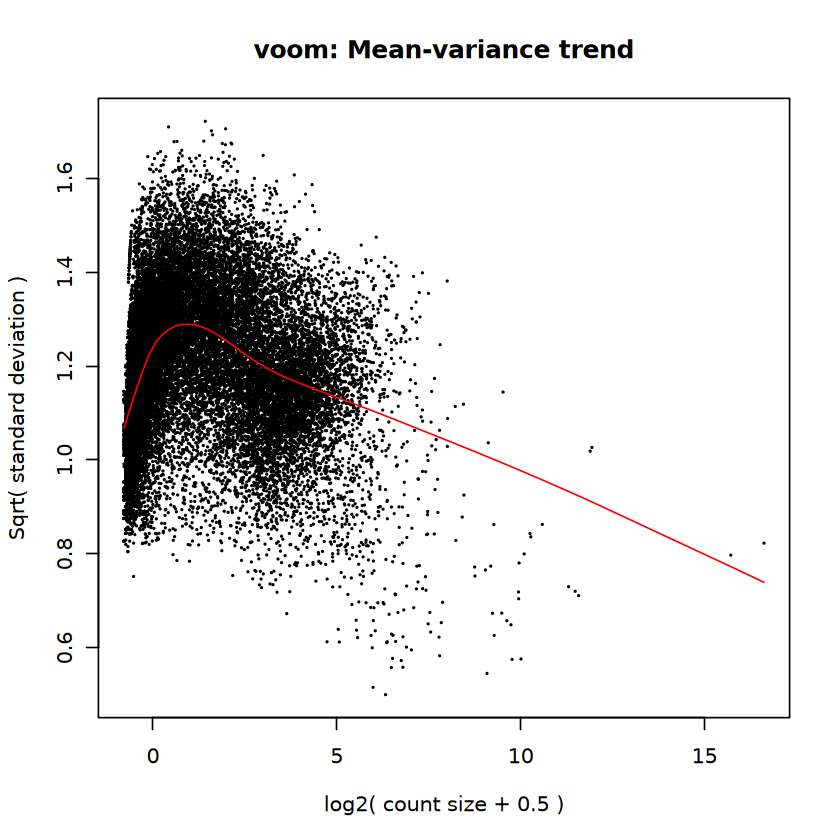

In [80]:
# Loop through each gene in gene_analysis_objects
for (gene_name in names(gene_analysis_objects)) {
  cat("\n=== Processing gene:", gene_name, "===\n")
  
  # Get the analysis object for this gene
  gene_obj <- gene_analysis_objects[[gene_name]]
  
  # Create DEG list
  d0 <- DGEList(gene_obj$counts)
  
  # Preprocess and normalize
  d0 <- calcNormFactors(d0)
  
  # Filter genes by expression
  keep1 <- filterByExpr(d0, gene_obj$design)
  keep2 <- rowSums(cpm_pre > 2) >= 2
  keep <- keep1 | keep2
    
  cat("Genes retained after filtering:", sum(keep), "\n")
  d <- d0[keep, ]
    
  # Obtain log-transformed normalized expression data
  logcpm <- cpm(d, prior.count = 2, log = TRUE)
  write.table(logcpm, 
              paste0("05_gene_counts/", gene_name, "_normalized_counts_batch1.txt"),
              sep = "\t", quote = FALSE)
  
  # Make design matrix column names syntactically valid
  colnames(gene_obj$design) <- make.names(colnames(gene_obj$design))
  
  # Voom transformation
  y <- voom(d, gene_obj$design, plot = TRUE)
  
  # Fit linear model
  fit <- lmFit(y, gene_obj$design)
  
  # Get all unique groups for this gene and make names valid
  unique_groups <- unique(gene_obj$metadata$group)
  unique_groups_valid <- make.names(unique_groups)
  cat("Unique groups:", paste(unique_groups, collapse = ", "), "\n")
  cat("Valid group names:", paste(unique_groups_valid, collapse = ", "), "\n")
  
  # Generate all possible pairwise comparisons
  if (length(unique_groups) > 1) {
    comparisons <- combn(unique_groups_valid, 2, simplify = FALSE)
  
    # Loop through each pairwise comparison
    for (comparison in comparisons) {
      group1 <- comparison[1]
      group2 <- comparison[2]
      
      # Get original group names for display
      orig_group1 <- unique_groups[unique_groups_valid == group1]
      orig_group2 <- unique_groups[unique_groups_valid == group2]
      
      cat("  Comparison:", orig_group1, "vs", orig_group2, "\n")
      
      # Define contrast
      contr <- makeContrasts(
        contrasts = paste0(group1, "-", group2),
        levels = gene_obj$design
      )
      
      # Estimate contrast for each gene
      tmp <- contrasts.fit(fit, contr)
      
      # Apply eBayes
      tmp <- eBayes(tmp)
      
      # Get results with multiple testing adjustment
      top.table <- topTable(tmp, adjust.method = "BH", sort.by = "P", n = Inf)
      
      # Count significant DEGs
      num_degs <- sum(top.table$adj.P.Val < 0.05)
      cat("    DEGs (adj.P.Val < 0.05):", num_degs, "\n")
      
      # Save results
      write.csv(top.table, 
                file = paste0("05_DEGs/", orig_group1, "_vs_", orig_group2, "_results.csv"),
                row.names = TRUE)
    }
  } else {
    cat("  Only one group found, skipping pairwise comparisons\n")
  }
}